# Learning continuous trajectories from sparse, irregular observations

**Goal.** Learn a single Neural ODE from several trajectories, each starting from a **different initial condition** and observed at only a few **randomly sampled times**.

We will use a simple 2D dynamical system rather than images, making it easy to see what the model actually learns.

The notebook illustrates:
1. The difference between *initial conditions*, *observation times*, and *dynamics*.
2. Training on irregularly sampled trajectory points.
3. Interpolating between observations and generalizing to unseen initial conditions.
4. Learning a **shared vector field**, not memorizing separate curves.


In [1]:
!pip install torchdiffeq

In [2]:
from torchdiffeq import odeint, odeint_adjoint

In [3]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 12
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


## 1. A known dynamical system (only used to generate data)

Our ground-truth ODE rotates points in the plane:

$$\frac{d}{dt}\begin{bmatrix}x\\y\end{bmatrix} =
\begin{bmatrix} -\omega y \\ \omega x\end{bmatrix},\qquad \omega=1.$$

Starting from $z_0=(x_0,y_0)$, the solution is:

$$z(t)=\begin{bmatrix}
 x_0\cos(\omega t)-y_0\sin(\omega t)\\
 x_0\sin(\omega t)+y_0\cos(\omega t)
\end{bmatrix}.$$

This analytic solution lets us evaluate whether the Neural ODE predicts the **unobserved** parts of each trajectory correctly. The model itself **never sees** the formula above or the derivatives.

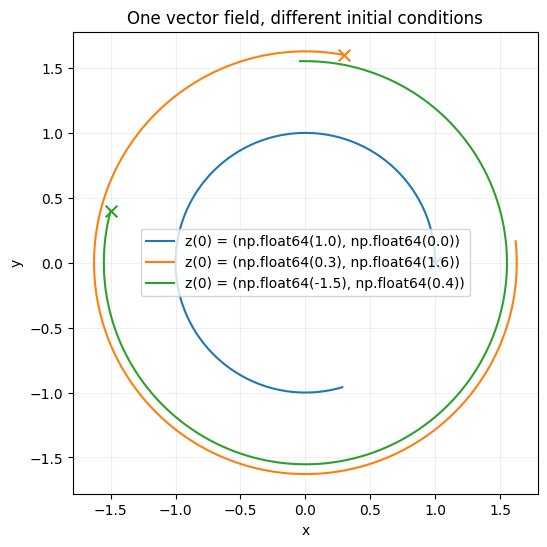

In [4]:
OMEGA = 1.0
T_END = 5.0

def true_solution(z0, t):
    """z0: (..., 2); t: (...) broadcastable to z0's leading shape."""
    x0, y0 = z0[..., 0], z0[..., 1]
    angle = OMEGA * t
    return np.stack([x0 * np.cos(angle) - y0 * np.sin(angle),
                     x0 * np.sin(angle) + y0 * np.cos(angle)], axis=-1)

# Demonstration: the same dynamics yields different curves for different z0.
t_dense = np.linspace(0, T_END, 300)
fig, ax = plt.subplots(figsize=(6, 6))
for z0 in [np.array([1.0, 0.0]), np.array([0.3, 1.6]), np.array([-1.5, 0.4])]:
    curve = true_solution(z0, t_dense)
    ax.plot(*curve.T, label=f"z(0) = {tuple(z0)}")
    ax.scatter(*z0, marker="x", s=70)
ax.set(xlabel="x", ylabel="y", title="One vector field, different initial conditions")
ax.axis("equal")
ax.grid(alpha=.2)
ax.legend()
plt.show()

## 2. Sparse, irregularly spaced observations

For each trajectory, we randomly choose:
- An initial position $z(0)$ (both radius and angle vary).
- Between **4 and 8 observations** in total, including the initial condition at $t=0$.
- The remaining observation times uniformly in $(0,T]$, independently for each trajectory.

Thus there is **no common sampling grid** across trajectories. The training data consist of pairs $(t_{ij}, z_i(t_{ij}))$, where $i$ indexes trajectories and $j$ indexes observations.

For simplicity we use noise-free observations here. Add noise later as an experiment.

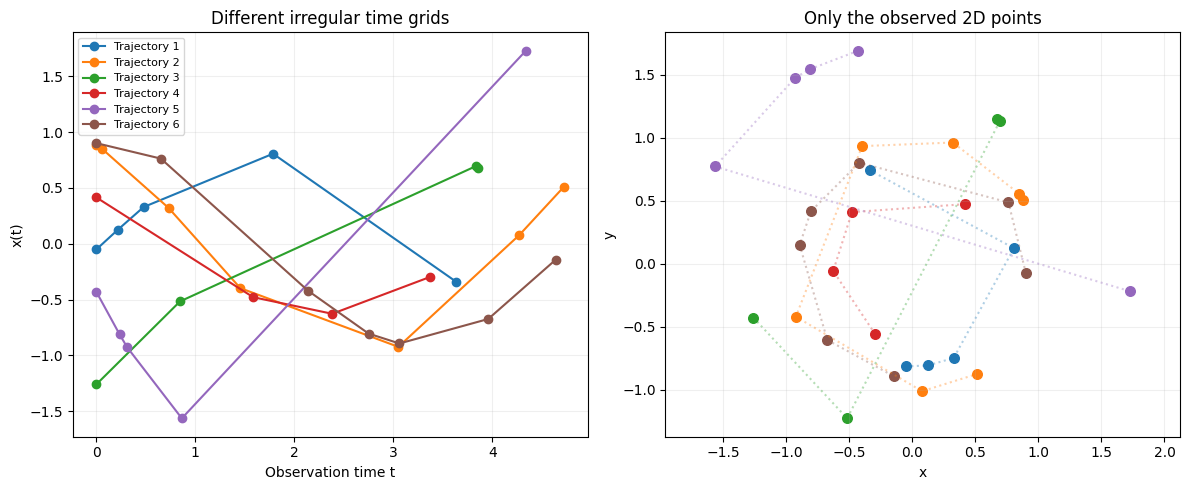

Observation times of first 3 trajectories:
0 [0.   0.22 0.48 1.78 3.63]
1 [0.   0.06 0.73 1.45 3.05 4.27 4.72]
2 [0.   0.85 3.83 3.85]


In [5]:
N_TRAIN = 80
N_TEST = 20
MAX_OBS = 8

def make_dataset(n_trajectories):
    """Produce zero-padded arrays and a mask for variable-length trajectories."""
    times = np.zeros((n_trajectories, MAX_OBS), dtype=np.float32)
    positions = np.zeros((n_trajectories, MAX_OBS, 2), dtype=np.float32)
    mask = np.zeros((n_trajectories, MAX_OBS), dtype=np.float32)
    initial = np.zeros((n_trajectories, 2), dtype=np.float32)

    for i in range(n_trajectories):
        radius = np.random.uniform(0.6, 2.0)
        angle = np.random.uniform(0, 2 * np.pi)
        z0 = np.array([radius * np.cos(angle), radius * np.sin(angle)])
        n_obs = np.random.randint(4, MAX_OBS + 1)
        t = np.r_[0.0, np.sort(np.random.uniform(0.05, T_END, n_obs - 1))]

        times[i, :n_obs] = t
        positions[i, :n_obs] = true_solution(z0, t)
        mask[i, :n_obs] = 1.0
        initial[i] = z0
    return dict(t=times, z=positions, mask=mask, z0=initial)

train_np = make_dataset(N_TRAIN)
test_np = make_dataset(N_TEST)

# Every color corresponds to one sampled trajectory.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i in range(6):
    valid = train_np['mask'][i].astype(bool)
    t = train_np['t'][i, valid]
    points = train_np['z'][i, valid]
    axes[0].plot(t, points[:, 0], 'o-', label=f'Trajectory {i+1}')
    axes[1].scatter(points[:, 0], points[:, 1], s=48, label=f'Trajectory {i+1}')
    axes[1].plot(points[:, 0], points[:, 1], ':', alpha=.35) # visual guide, NOT continuous truth
axes[0].set(xlabel='Observation time t', ylabel='x(t)', title='Different irregular time grids')
axes[1].set(xlabel='x', ylabel='y', title='Only the observed 2D points')
for a in axes: a.grid(alpha=.2)
axes[1].axis('equal')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
print('Observation times of first 3 trajectories:')
for i in range(3):
    print(i, np.round(train_np['t'][i, train_np['mask'][i].astype(bool)], 2))

## 3. A Neural ODE as a learned vector field

Instead of learning a separate curve for each trajectory, learn a *shared* differential equation

$$\dot z(t)=f_\theta(z(t)),\qquad z(0)=z_0,$$

where $f_\theta:\mathbb{R}^2\to\mathbb{R}^2$ is a small multilayer perceptron. Its output is the **instantaneous velocity** $(\dot x,\dot y)$, *not* the next position.

In [6]:
class VectorField(nn.Module):
    def __init__(self, width=48):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, width), nn.Tanh(),
            nn.Linear(width, width), nn.Tanh(),
            nn.Linear(width, 2),
        )

    def forward(self, t, z):
        return self.net(z)

def predict_at_observations(field, initial, times):
    # initial: (B, 2)
    # times:   (B, MAX_OBS)

    predictions = []

    for i in range(len(initial)):
        # Remove repeated times introduced by padding
        t, inverse = torch.unique(
            times[i], sorted=True, return_inverse=True
        )

        # Solve the ODE at observation times
        z = odeint_adjoint(field, initial[i], t, method="dopri5")

        # Restore padded positions
        predictions.append(z[inverse])

    return torch.stack(predictions, dim=0)


def tensor_dataset(data):
    return {k: torch.tensor(v, device=DEVICE) for k, v in data.items()}

# Replace zero padding with the last observed time: avoids integrating backwards
# through padded slots. Padded predictions are still excluded from the loss.
def prepare(data):
    d = {k: np.array(v, copy=True) for k, v in data.items()}
    for i in range(len(d['t'])):
        count = int(d['mask'][i].sum())
        d['t'][i, count:] = d['t'][i, count-1]
    return tensor_dataset(d)

train = prepare(train_np)
test = prepare(test_np)
model = VectorField().to(DEVICE)
print(model)

VectorField(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=48, bias=True)
    (1): Tanh()
    (2): Linear(in_features=48, out_features=48, bias=True)
    (3): Tanh()
    (4): Linear(in_features=48, out_features=2, bias=True)
  )
)


## 4. Training on observation points only

For each trajectory, start from its **known initial state** $z_i(0)$, integrate the learned ODE to the observed times, and compare with the observed locations:

$$L(\theta)=\frac{\sum_{i,j}m_{ij}\,\|\hat z_i(t_{ij})-z_i(t_{ij})\|_2^2}{2\sum_{i,j}m_{ij}}.$$

The mask $m_{ij}$ is 1 for real observations and 0 for padding. We never train on the hidden dense trajectories.

There is deliberately **no image encoder or decoder**: the 2D observed points are already the state. This isolates the central Neural ODE idea.

Epoch   25/150  training MSE = 0.643391
Epoch   50/150  training MSE = 0.170657
Epoch   75/150  training MSE = 0.035916
Epoch  100/150  training MSE = 0.046737
Epoch  125/150  training MSE = 0.011434
Epoch  150/150  training MSE = 0.008177
Unseen trajectories: observed-point test MSE = 0.004821


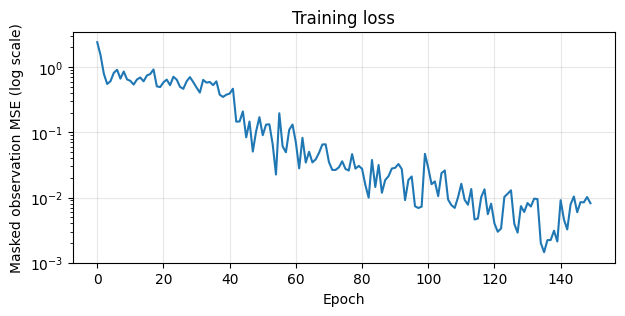

In [7]:
def masked_mse(pred, target, mask):
    squared_error = (pred - target).square().sum(dim=-1)
    return (squared_error * mask).sum() / (2 * mask.sum())

optimizer = torch.optim.Adam(model.parameters(), lr=0.008)
EPOCHS = 150
BATCH_SIZE = 8
history = []

for epoch in range(EPOCHS):
    model.train()
    optimizer.zero_grad()
    # Random mini-batch instead of integrating all 80 trajectories
    idx = torch.randperm(len(train['z0']), device=DEVICE)[:BATCH_SIZE]
    pred = predict_at_observations(model, train['z0'][idx], train['t'][idx])
    loss = masked_mse(pred, train['z'][idx], train['mask'][idx])
    loss.backward()
    optimizer.step()
    history.append(loss.item())
    if (epoch + 1) % 25 == 0:
        print(f"Epoch {epoch+1:4d}/{EPOCHS}  training MSE = {loss.item():.6f}")

model.eval()
with torch.no_grad():
    test_pred = predict_at_observations(model, test['z0'], test['t'])
    test_loss = masked_mse(test_pred, test['z'], test['mask']).item()
print(f"Unseen trajectories: observed-point test MSE = {test_loss:.6f}")

plt.figure(figsize=(7, 3))
plt.plot(history)
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Masked observation MSE (log scale)')
plt.title('Training loss')
plt.grid(alpha=.3)
plt.show()

## 5. Dense predictions between sparse observations

We now integrate the learned ODE on a **dense time grid**, even though training used only a few random observation times. Compare:
- Solid curve: **ground-truth continuous trajectory** (used only for evaluation).
- Dashed curve: **Neural ODE prediction**.
- Dots: **observed training/test data**.
- Cross: initial condition.

The second row contains **previously unseen initial conditions** (held-out trajectories).

In [8]:
def dense_predict(z0_np, t_np):
    z0 = torch.as_tensor(
        z0_np, dtype=torch.float32, device=DEVICE
    ).reshape(1, 2)

    t = torch.as_tensor(t_np, dtype=torch.float32, device=DEVICE)

    model.eval()
    with torch.no_grad():
        solution = odeint(model, z0, t, method="dopri5")

    return solution[:, 0, :].cpu().numpy()

## 6. Did it learn the underlying dynamics?

Interpolating points is not enough by itself to prove the correct dynamics were identified. An additional diagnostic is the learned **vector field** $f_	heta(x,y)$: visualize its predicted velocity at a grid of positions and compare it with the real rotation field. The Neural ODE should approximately capture the circular structure near the training region.

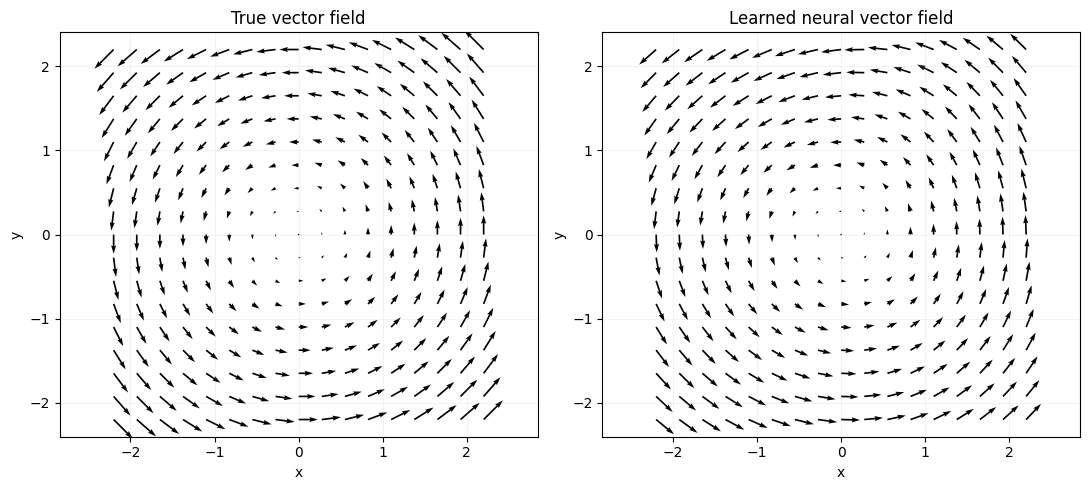

In [10]:
grid = np.linspace(-2.2, 2.2, 17)
X, Y = np.meshgrid(grid, grid)
points = np.stack([X.ravel(), Y.ravel()], axis=-1)
with torch.no_grad():
    learned_vel = model(
    0.0,
    torch.tensor(points, dtype=torch.float32, device=DEVICE)
    ).cpu().numpy()
true_vel = np.stack([-OMEGA * points[:, 1], OMEGA * points[:, 0]], axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, vel, title in zip(axes, [true_vel, learned_vel], ['True vector field', 'Learned neural vector field']):
    ax.quiver(X, Y, vel[:, 0].reshape(X.shape), vel[:, 1].reshape(Y.shape))
    ax.set(xlabel='x', ylabel='y', title=title)
    ax.axis('equal')
    ax.grid(alpha=.15)
plt.tight_layout()
plt.show()

## 7. Exercises and limitations

**Experiments:**

1. Change `N_TRAIN` from 80 to 10. How does held-out performance change?
2. Reduce observations to **2–3 per trajectory**. Which parts of the motion become ambiguous?
3. Increase `T_END` beyond a full revolution. Why can sparse observations alias periodic motion?
4. Add Gaussian noise to the observations in `make_dataset`. Does the Neural ODE smooth out the noise?
5. Change the system to a **damped spiral**, e.g. $\dot x=-\alpha x-\omega y$, $\dot y=\omega x-\alpha y$. What changes in the trajectories and vector field?
6. Change `EPOCHS`, `width`, or the number of RK4 substeps and compare runtime with prediction accuracy.

**Interpretation:** We learn one shared autonomous ODE and use the observed initial state to generate each trajectory. We are not learning an encoder for an unobserved initial state. In a real sparse/noisy dataset, initial-state inference may need its own recognition network, which is the key extra component in latent Neural ODE models. Also, accurate interpolation in the observed region does not guarantee accurate extrapolation or unique recovery of the physical dynamics.